# Analysis of 2026 pastry data
The following bakeries were included:
- `Bread Chic`
- `La Creperie`
- `Phillippe`
- `Trickster`
- `Little Bird`

In addition, the following negative controls were used:
- `Lamar donut (regular)`
- `Lamar donut (cake)`
- `King Soopers`
- `Bread (homemade)`

### Metrics
The metrics from the analysis in `2024` are carried over and augmented with a new metric: `spring exponential doughcay`. This is the half-life of an exponential decay curve fit to measured croissant heights following successive squishes with my finger.

The theory is a doughy, underbaked croissant will have a very short half-life (no supporting structure), while a very overbaked, bready croissant will have a very long half-life (lots of spring/structure). An ideal croissant is somewhere in between.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import altair as alt
import matplotlib.pyplot as plt
import warnings

In [2]:
# load up the data

DATA_PATH = Path().resolve().parent / "data" / "2026" / "croissant_data.csv"
data = pd.read_csv(DATA_PATH)

In [3]:
bakeries = sorted(set(data.bakery))

# init the accumulator per bakery
all_bakery_metrics = {bakery: {} for bakery in bakeries}

print(f"Analyzing the following bakeries:\n{bakeries}")

Analyzing the following bakeries:
['bread', 'bread chic', 'king soopers', 'la creperie', 'lamar - cake', 'lamar - regular', 'little bird', 'phillippe', 'trickster']


In [4]:
plot_order = [
    "bread", "lamar - regular", "lamar - cake",
    "king soopers", "little bird", "trickster",
    "phillippe", "bread chic", "la creperie"
]

## Chew

In [5]:
from pytiserie.spring import compute_spring_metrics, exponential, double_exponential

In [6]:
def get_spring_measurements(data: pd.DataFrame) -> pd.DataFrame:
    df = data.loc[data.metric.str.startswith("height_")]
    df['t'] = df.metric.str.split("_").str[-1].str[-1].astype(int)  # starting with t=0
    df = df.sort_values(by='t', ascending=True)
    return df

In [7]:
spring_data = get_spring_measurements(data)


typ = "double"
interpolant = {"bakery": [], "t": [], "y": []}


for (bakery, df) in spring_data.groupby('bakery'):
    double = typ == "double"
    y = df['value'].values
    t = np.arange(len(y))

    metrics = compute_spring_metrics(y, double=double)
    params = metrics.pop("params")

    # make an interpolant to visualize the fitted curve
    interpolated = np.arange(0, len(df), 0.1)
    func = double_exponential if double else exponential
    fitted_values = func(interpolated, *params)
    interpolant['bakery'].extend([bakery] * len(interpolated))
    interpolant['t'].extend(interpolated)
    interpolant['y'].extend(fitted_values)

    # update the bakery metrics
    all_bakery_metrics[bakery].update(**metrics)

interpolant = pd.DataFrame(interpolant)

In [8]:
base = (
    alt.Chart(spring_data.loc[spring_data['t'].le(8)])
    .transform_window(
        initial_value="first_value(value)",
        sort=[{"field": "t"}],
        groupby=["bakery"],
    )
    .transform_calculate(normalized="datum.value / datum.initial_value")
    .mark_line(size=3, opacity=0.5)
    .encode(
        x='t:Q',
        y='normalized:Q',
        color=alt.Color('bakery', sort=plot_order)
    )
)

fit = (
    alt.Chart(interpolant)
    .transform_window(
        initial_value="first_value(y)",
        sort=[{"field": "t"}],
        groupby=["bakery"],
    )
    .transform_calculate(normalized="datum.y / datum.initial_value")
    .mark_line(size=2, strokeDash=[5, 5])
    .encode(
        x=alt.X('t:Q', title="# of squishes"),
        y=alt.Y('normalized:Q', title="relative height"),
        color=alt.Color('bakery', sort=plot_order)
    )
    .properties(title=f"fitted {typ} exponential curve")
)

chart = base + fit
chart.display()

alt.LayerChart(...)

## Color

In [9]:
from pytiserie.color import compute_color_metrics

In [10]:
FGD_BKGD_REGEX = r"(?:color_mean_|color_std_)\s*(.*)$"

def extract_color_data(croissant_data: pd.DataFrame) -> pd.DataFrame:
    color_data = croissant_data.loc[croissant_data['metric'].str.startswith("color")].copy()
    color_data['object'] = color_data['metric'].str.extract(FGD_BKGD_REGEX)
    return color_data

In [11]:
color_data = extract_color_data(data)

color_ratio_plot_data = {
    "bakery": [],
    "ratio_mean": [],
    "ratio_low": [],
    "ratio_high": []
}

for (bakery, df) in color_data.groupby("bakery"):
    metrics = compute_color_metrics(df)
    all_bakery_metrics[bakery].update(**metrics)

    color_ratio_plot_data["bakery"].append(bakery)
    color_ratio_plot_data['ratio_mean'].append(metrics['color_ratio_mean'])
    color_ratio_plot_data['ratio_low'].append(metrics['color_ratio_low'])
    color_ratio_plot_data['ratio_high'].append(metrics['color_ratio_high'])

color_ratio_plot_data = pd.DataFrame(color_ratio_plot_data)

In [12]:
mu = (
    alt.Chart(color_ratio_plot_data)
    .mark_point(filled=True, size=80)
    .encode(
        x=alt.X('ratio_mean', title="color ratio").scale(domain=[0, 1]),
        color=alt.Color('bakery', sort=plot_order),
        y=alt.Y('bakery', sort=plot_order)
    )
    .properties(width=250, height=150)
)

sd = (
    alt.Chart(color_ratio_plot_data)
    .mark_line()
    .encode(
        x='ratio_low',
        x2='ratio_high',
        color=alt.Color('bakery', sort=plot_order),
        y=alt.Y('bakery', sort=plot_order)
    )
)

(sd + mu).display()

alt.LayerChart(...)

## Cavity

In [13]:
from pytiserie.lamination import compute_lamination_peak_metrics
from pytiserie.utils import make_gauss_kernel

In [14]:
def extract_lamination_data(croissant_data: pd.DataFrame) -> pd.DataFrame:
    lamination_data = croissant_data.loc[croissant_data['metric'].str.startswith("linescan")].copy()
    lamination_data['direction'] = lamination_data['metric'].str.split("_").str[1]
    lamination_data['order'] = lamination_data['metric'].str.split("_").str[-1]
    lamination_data['order'] = lamination_data['order'].astype(int)
    return lamination_data.sort_values(by=['order', 'direction'], ascending=True)

In [15]:
lamination_data = extract_lamination_data(data)

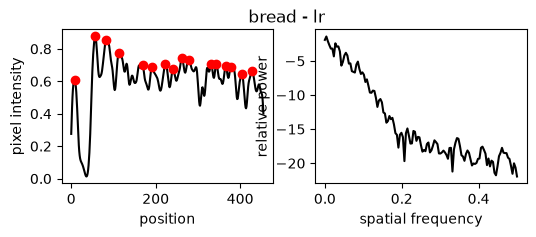

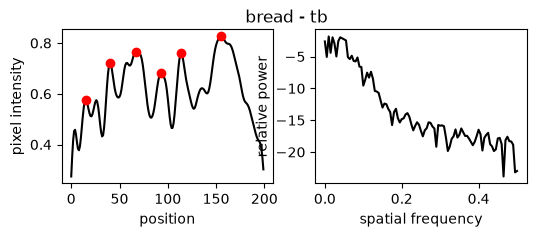

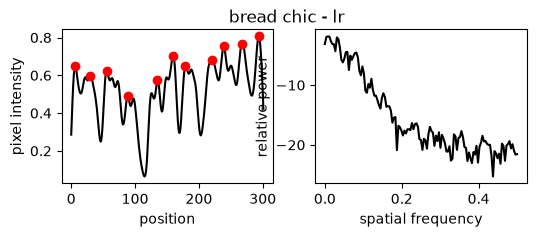

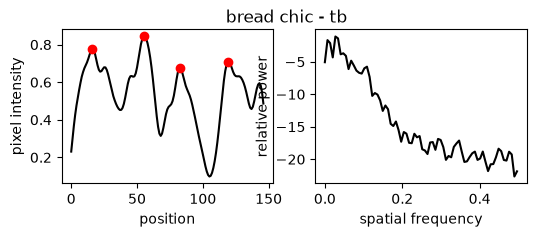

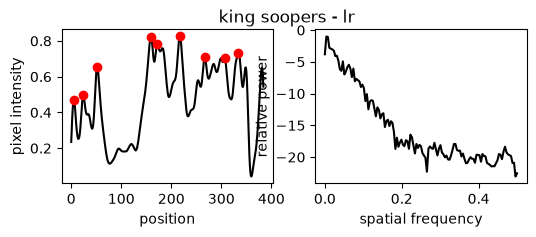

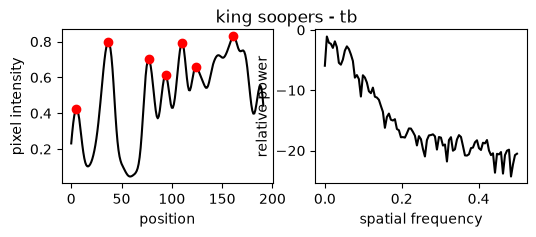

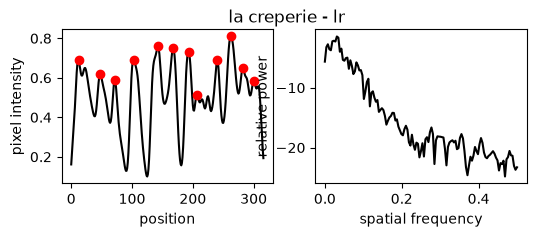

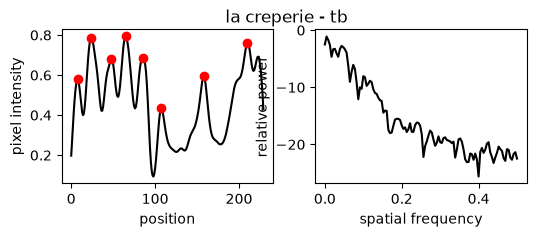

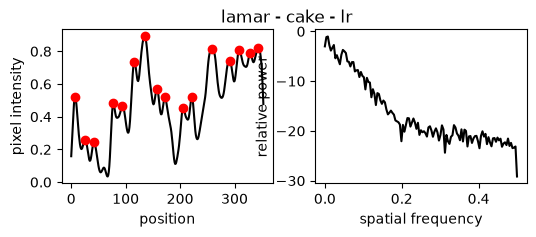

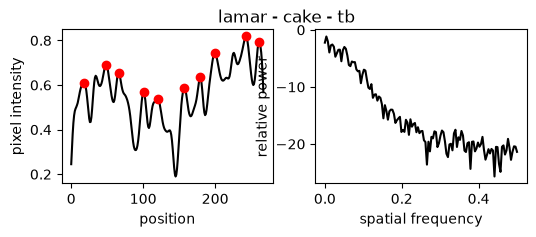

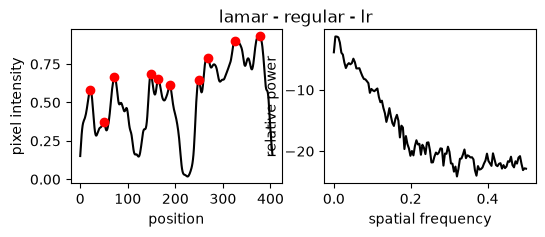

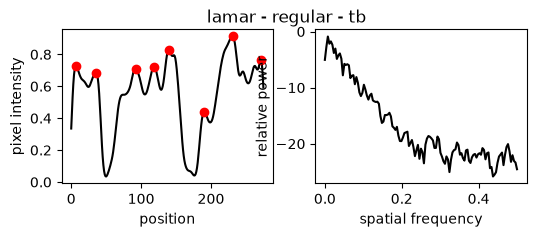

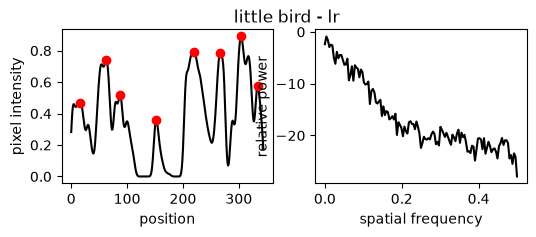

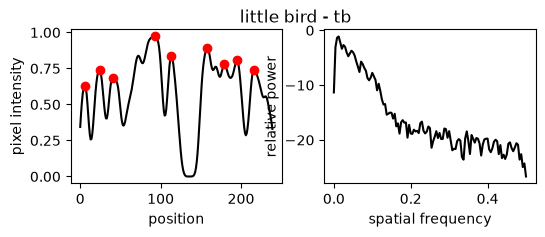

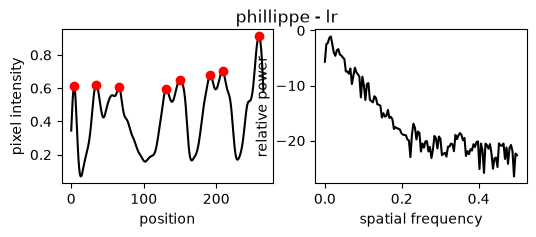

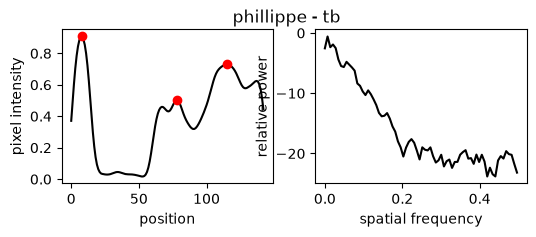

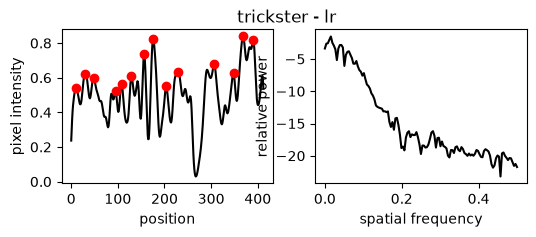

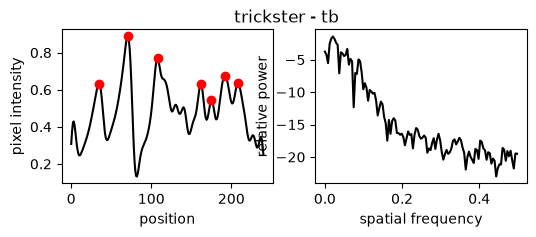

In [20]:
peak_width = 5  # 5 pixels
prominence = 0.05
smoothing_kernel = make_gauss_kernel(15, 3)  # 25-pixel smoothing kernel with a 10-pixel sigma

show_diagnostics = True

with warnings.catch_warnings():
    warnings.filterwarnings("ignore")
    for (bakery, df) in lamination_data.groupby("bakery"):
        vals = []

        for (direction, direction_df) in df.groupby("direction"):
            linescan = direction_df['value'].values
            tmp, diagnostics = compute_lamination_peak_metrics(
                linescan, smoothing_kernel=smoothing_kernel, width=peak_width, prominence=prominence
            )
            vals.append(list(tmp.values()))

            if show_diagnostics:
                # plot the line scan with peaks, and the fourier distribution
                fig, ax = plt.subplots(1, 2, figsize=(6, 2), dpi=100)
                ax[0].plot(diagnostics['linescan'], 'k')
                ax[0].plot(diagnostics['peaks'], diagnostics['linescan'][diagnostics['peaks']], 'ro')
                ax[0].set_xlabel("position")
                ax[0].set_ylabel("pixel intensity")

                ax[1].plot(diagnostics["freq"], np.log(diagnostics["psd"]), 'k')
                ax[1].set_xlabel("spatial frequency")
                ax[1].set_ylabel("relative power")

                fig.suptitle(f"{bakery} - {direction}")

        # take the avg between left-right & top-down
        vals = np.mean(vals, axis=0)
        all_bakery_metrics[bakery].update(
            **{f"{metric}": vals[i] for i, metric in enumerate(tmp.keys())}
        )

## Crunch

In [21]:
from pytiserie.audio import compute_crisp_metrics
from pytiserie.utils import read_audio_data

In [22]:
fname2bakery = {
    "la_creperie": "la creperie",
    "bread": "bread",
    "king_soopers": "king soopers",
    "lamar_cake": "lamar - cake",
    "lamar_regular": "lamar - regular",
    "phillippe": "phillippe",
    "bread_chic": "bread chic",
    "trickster": "trickster",
    "littlebird": "little bird"
}

audio_path = Path().resolve().parent / "assets" / "audio" / "2026"
audio_files = list(audio_path.glob("*.flac"))

In [23]:
ref_time_block = (0.25, 1)
db_threshold = 10
smoothing_window = 0.05  # moving average over this many seconds
max_gap = 0.25  # maximum time allowed for dips in the thresholded dB to be merged
min_length = 0.5  # minimum length of the crisp to be considered real

show_diagnostics = False

for file in audio_files:
    name = file.name
    bakery = fname2bakery.get(name.replace("_crisp.flac", ""), None)
    if bakery is None:
        print(f"issue mapping bakery to {name}")
        continue

    # read in the audio
    audio_data, sr = read_audio_data(file)

    # remove the very beginning and end, which have some artifacts
    audio_data = audio_data.loc[int(sr * 0.5):len(audio_data)-int(sr * 1)]
    audio_data['time'] = audio_data['time'] - audio_data['time'].min()

    smoothing_kernel = np.ones(int(smoothing_window * sr))
    crisp_metrics, diagnostics = compute_crisp_metrics(
        audio_data, ref_time_block, db_threshold, smoothing_kernel=smoothing_kernel, max_gap=max_gap, min_length=min_length
    )
    all_bakery_metrics[bakery].update(**crisp_metrics)

    # plot the audio, DB & start/stop
    if show_diagnostics:
        fig = plt.figure(figsize=(4, 1.5), dpi=120)
        fig.suptitle(bakery)
        plt.plot(audio_data['time'], diagnostics['db'], 'k')
        plt.hlines(db_threshold, diagnostics['crisp_start'], diagnostics['crisp_end'], 'r', linewidth=3, alpha=0.75)
        plt.xlabel("time (s)")
        plt.ylabel("dB")

***

## Dim Redux & Viz

In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import SparsePCA, NMF

In [42]:
metrics_df = pd.DataFrame(all_bakery_metrics).T

# remove eval columns
metrics_df = metrics_df.drop(
    columns=['spring_decay_mse', 'spring_decay_r_squared', 'spring_decay_aic']
)

# derive a few additional columns
metrics_df["color_ratio_sd"] = metrics_df['color_ratio_mean'] - metrics_df["color_ratio_low"]
metrics_df["spring_decay_halflife_ratio"] = metrics_df["spring_decay_halflife"] / metrics_df["spring_decay_halflife_2"]

# drop redundant ones
metrics_df = metrics_df.drop(
    columns=["color_ratio_low", "color_ratio_high", "spring_decay_halflife", "spring_decay_halflife_2"]
)
metrics_df.fillna(0, inplace=True)

,color_ratio_mean,rel_num_peaks,peak_size_mean,peak_size_std,cavity_size_mean,cavity_size_std,frequency_entropy,avg_crisp_db,max_crisp_db,crisp_duration,color_ratio_sd,spring_decay_halflife_ratio
bread,0.557927,0.032544,19.437741,15.663806,28.000000,10.101647,2.424785,0.000000,0.000000,0.000000,0.173297,0.996718
bread chic,0.454194,0.031817,17.817993,5.726320,31.566667,6.661905,2.116478,16.062674,35.568024,1.714333,0.114654,1.000200
king soopers,0.474315,0.029917,17.997264,16.318947,33.562500,19.106913,1.926852,13.220499,24.188203,1.009083,0.136241,0.228369
la creperie,0.456799,0.036319,15.665498,10.208958,27.519481,11.073223,2.232915,19.183582,40.086788,2.850979,0.126623,1.000226
lamar - cake,0.584691,0.041256,14.815872,13.027920,24.733333,8.271374,2.113334,0.000000,0.000000,0.000000,0.085636,0.048955
lamar - regular,0.607151,0.026838,29.886882,33.954824,38.634921,16.431422,1.803470,0.000000,0.000000,0.000000,0.071068,0.075942
little bird,0.408906,0.030344,18.650798,11.627719,35.839286,14.062620,1.936308,25.384781,37.373926,1.778687,0.139441,0.162335
phillippe,0.600281,0.025527,19.751730,11.085423,44.964286,16.209079,1.677111,20.448763,29.951225,1.391271,0.123190,0.999912
trickster,0.597282,0.031472,16.379982,9.815089,29.032051,15.725361,2.450839,23.859777,35.494619,1.641792,0.147828,0.242659


In [44]:
X = StandardScaler(with_mean=True).fit_transform(metrics_df)
pca = SparsePCA(n_components=3, alpha=0.5, random_state=42)
# pca = NMF(n_components=3, init='nndsvd', alpha_W=0.1, alpha_H=0.1, max_iter=1000, l1_ratio=0.25)
X = pca.fit_transform(X)
proj_df = pd.DataFrame(X, columns=[f"pc{i+1}" for i in range(pca.n_components_)])
proj_df['bakery'] = metrics_df.index

In [46]:
alt.Chart(proj_df).mark_point(filled=True, size=100).encode(
    x='pc1', y='pc2',
    color=alt.Color('bakery', sort=plot_order),
    tooltip=['bakery']
)

alt.Chart(...)

In [47]:
component_df = pd.DataFrame(pca.components_, columns=metrics_df.columns, index=[f"pc{i+1}" for i in range(pca.n_components_)])

In [48]:
alt.Chart(
    component_df.reset_index().melt(
        id_vars=['index'], var_name='metric', value_name='loading'
    )
).mark_bar().encode(
    x=alt.X('loading'),
    y=alt.Y('metric:N'),
    color=alt.Color("loading").scale(scheme='blueorange'),
    column=alt.Column('index', title='component #')
).properties(
    width=100
)

alt.Chart(...)

## Cosine (dis)similarity
An ideal croissant should be the most jointly dissimilar from all of the negative controls

In [49]:
from sklearn.metrics.pairwise import cosine_similarity

In [50]:
# apply it to the reduced dim to avoid overfitting to sparse feature space
similarity_matrix = cosine_similarity(X, X)
similarity_df = pd.DataFrame(similarity_matrix, index=metrics_df.index, columns=metrics_df.index)

In [51]:
alt.Chart(
    similarity_df.reset_index(names='bakery_i').melt(
        id_vars=['bakery_i'], var_name='bakery_j', value_name='similarity'
    )
).mark_rect().encode(
    x=alt.X('bakery_i', sort=plot_order),
    y=alt.Y('bakery_j', sort=plot_order),
    color=alt.Color('similarity').scale(scheme='blueorange', domain=[-1, 1])
).properties(width=300, height=300)

alt.Chart(...)

In [52]:
# which croissants are most jointly dissimilar from the negative controls?
control_conditions = {
    "doughy": ["lamar - regular", "lamar - cake"],
    "bready": ["bread"],
    "industrialized": ["king soopers"],
    "overall": ["king soopers", "bread", "lamar - regular"]
}

results = np.zeros((len(bakeries), len(control_conditions)))

for i, (condition, controls) in enumerate(control_conditions.items()):
    similarity = 1 - (1 - similarity_df.loc[:, controls].mean(axis=1)) / 2
    results[:, i] = similarity

results = pd.DataFrame(results, index=similarity_df.index, columns=control_conditions.keys())

In [53]:
alt.Chart(
    results.loc[
        ["trickster", "bread chic", "phillippe", "la creperie", "little bird"]
    ].reset_index(names='bakery').melt(
        id_vars=['bakery'], var_name='control', value_name='similarity'
    )
).mark_bar().encode(
    y=alt.Y('bakery', sort=plot_order),
    x=alt.X('similarity').scale(domain=[0, 1]),
    color=alt.Color('bakery', legend=None, sort=plot_order),
    column='control'
).properties(width=60, height=100)

alt.Chart(...)

In [54]:
results.sort_values(by=['overall'], ascending=True)

,doughy,bready,industrialized,overall
la creperie,0.221677,0.406326,0.337437,0.252273
bread chic,0.207971,0.403036,0.355929,0.256895
trickster,0.198804,0.439032,0.345532,0.263127
little bird,0.227229,0.078167,0.826454,0.407151
lamar - cake,0.789621,0.687550,0.122017,0.462937
bread,0.589636,1.000000,0.163507,0.551743
phillippe,0.327350,0.282249,0.962985,0.620278
king soopers,0.413160,0.163507,1.000000,0.622604
lamar - regular,0.789621,0.491721,0.704304,0.732008


### How do these scores match with subjective preferences?

In [55]:
def extract_subjective_scores(croissant_data: pd.DataFrame) -> pd.DataFrame:
    scores = croissant_data.loc[croissant_data.metric.eq("flavor")].copy()
    # pivot so j.u. & k.u. are each columns
    scores = scores.pivot(index='bakery', columns='units', values='value')
    # rename the units to avoid breaking pandas/altair
    scores = scores.rename(columns={'j.u.': 'jordan', 'k.u.': 'kendra'})
    scores['avg'] = scores[['jordan', 'kendra']].mean(axis=1)
    return scores

In [56]:
scores = extract_subjective_scores(data)
results_with_scores = results.merge(scores, left_index=True, right_index=True).reset_index(names='bakery')
melted = results_with_scores.melt(
    id_vars=['bakery', 'jordan', 'kendra', 'avg'],
    var_name='control',
    value_name='similarity'
)

In [57]:
person = "avg"
which = ['trickster', 'phillippe', 'la creperie', 'bread chic', 'little bird']

df = melted.loc[melted.bakery.isin(which)].copy()

base = (
    alt.Chart(df)
    .mark_point(filled=True, size=100)
    .encode(
        x=alt.X('similarity').scale(domain=[0, 1]),
        y=alt.Y(person, title=f"{person} score").scale(domain=[5, 10]),
        color=alt.Color('bakery', sort=plot_order)
    )
)

regression = (
    alt.Chart(df)
    .transform_regression(
        "similarity", person, as_=["similarity", person]
    )
    .mark_line(color='grey')
    .encode(
        x='similarity',
        y=person
    )
)

(base + regression).properties(width=120, height=100).facet("control")

alt.FacetChart(...)

## Which croissants give the best bang/buck?

In [37]:
# weight vs. cost
weights_and_costs = data.loc[
    data.metric.isin(['weight', 'cost'])
    & data.bakery.isin(which)
]
weights_and_costs = weights_and_costs.pivot(
    index='bakery', columns='metric', values='value'
).reset_index()

weights_and_costs['cost_weight_ratio'] = weights_and_costs['cost'] / weights_and_costs['weight']

In [38]:
alt.Chart(weights_and_costs).mark_bar(size=40).encode(
    x=alt.X("bakery", sort='y'),
    y='cost_weight_ratio',
    color=alt.Color("bakery", sort=plot_order, legend=None)
).properties(width=250, height=100)

alt.Chart(...)

In [39]:
# score vs cost

weights_and_costs = weights_and_costs.merge(
    scores.reset_index()[['bakery', 'avg']],
    on='bakery'
)
weights_and_costs['cost_score_ratio'] = weights_and_costs['cost'] / weights_and_costs['avg']

alt.Chart(weights_and_costs).mark_bar(size=40).encode(
    x=alt.X("bakery", sort='y'),
    y='cost_score_ratio',
    color=alt.Color("bakery", sort=plot_order, legend=None)
).properties(width=250, height=100)

alt.Chart(...)